# The bowling response in the powerplay

**The question, given the earlier findings.** The powerplay six rate rose about 40% at no wicket cost, half of it the same openers and half recruitment, all of it in the air. A bowling coach's question is whether there was a line-and-length answer: were there deliveries that held through the surge, deliveries that were punished, and did bowlers move toward or away from them? Before any of that can be read, one prior question has to be settled: did the extra sixes come from *what* was bowled (a changed mix of lengths, lines, speeds and types) or from *every* class of delivery being hit harder? The first would be a coaching finding; the second would say the answer lies in selection and matchup rather than execution.

**What this notebook does.**
1. Checks that the tag columns' coverage is the same in both seasons, so a mix change cannot be a tagging change, and sizes the coarse classes.
2. Splits the season change in each rate against deliveries (six rate, runs per ball, dot rate, wicket rate) exactly into a *within-class* component (every class got hit harder) and a *mix* component (bowlers bowled a different mix), for six dimensions (line by length, length, line, delivery type, speed band, release band), for all bowlers and for pace and spin separately, under the match bootstrap on shared draws.
3. Lays out the delivery menu: each class's share of powerplay deliveries in both seasons, its rates, the changes with intervals, and a thin flag; and the line-by-length grid.
4. Asks whether the same bowlers conceded more or different bowlers bowled the powerplay, with the same exact decomposition used for batters.

**How to read this notebook.** Rates are per legal delivery in the powerplay (a wide or no-ball is not a legal delivery and carries no line or length tag). Length is coarsened to full, good and short; line to off side, stumps and leg side; speed to over 140, 130 to 140 and under 130 kph; release point to above and below 2.0 metres; type to the nine families from the validation step. Line, length and type are hand-tagged (several percent error, stable across seasons); speed and release are tracked and bowled almost entirely by pace, so those two are read on pace deliveries. A class is *thin* below 300 balls in either season and its rates are descriptive. The class a bowler chooses depends on the batter and the state, so the menu describes what happened to each class, not what would have happened had it been bowled more.

**Numbers in the text.** Quoted from the run of 13 September 2026 under the seed in `config.toml`; if a table disagrees with a paragraph, the table is current. Code lives in `scripts/bowling_response/` and `scripts/batter_continuity/`.

In [1]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("scripts").resolve()))

from common.config import load_settings
from common import results_io
from common import derived_columns as dc
from mean_level_and_tail import season_contrast_bootstrap as scb
from bowling_response import delivery_classes as classes
from bowling_response import mix_or_menu as mm
from batter_continuity import six_rate_decomposition as continuity

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

settings = load_settings()
ANALYSIS = "bowling_response"
SEED = settings.seed("global")
N_ITER = settings.n_resamples
CFG = settings.section("bowling_response")
PRODUCER = "bowling_response.ipynb"
YEARS = (settings.earlier_season, settings.later_season)
print(f"root={settings.root}  seed={SEED}  resamples={N_ITER}  thin floor={CFG['thin_class_floor']}  bowler floor={CFG['bowler_min_balls']}")

root=/Users/madkad/dpl_2026_s1  seed=202609081209  resamples=10000  thin floor=300  bowler floor=60


## Data

In [2]:
DATA_PATH = settings.data_path("cleaned_dataset")
USING_FIXTURE = not DATA_PATH.exists()
if USING_FIXTURE:
    from common.synthetic_ballframe import make_synthetic_ballframe
    df = make_synthetic_ballframe(seed=7)
    print("REAL DATA ABSENT: running on the synthetic fixture (mechanics only, no findings)")
else:
    df = scb.load_cleaned_dataset(str(DATA_PATH))
print(f"rows={len(df):,}  matches={df['p_match'].nunique()}")
EXTRA = {"n_resamples": N_ITER, "fixture": USING_FIXTURE, **CFG}

rows=34,967  matches=145


## Coverage and cell sizes

Blank rates of the five tag columns on powerplay deliveries by season and bowler kind, then balls and sixes per coarse line-by-length cell per season.

In [3]:
pp = scb.in_phase(df, settings.phase("powerplay"))
pp = pp.to_numpy() if hasattr(pp, "to_numpy") else np.asarray(pp)
coverage = classes.coverage_by_season(df, pp)
results_io.write_table(coverage, settings, ANALYSIS, "tag_coverage_powerplay", SEED, PRODUCER, EXTRA)
display(coverage)
tagged = classes.assign_classes(df)
legal = dc.is_legal_delivery(tagged).to_numpy()
six = dc.is_six(tagged).to_numpy()
cells = (tagged[pp & legal].assign(six=six[pp & legal])
         .groupby(["year", "length3", "line3"]).agg(balls=("six", "size"), sixes=("six", "sum"), six_rate=("six", "mean")).round(3))
cells

,year,bowl_kind,line,length,bowl_type,bowl_speed_category,bowl_release_point
0,2023,all,0.0011,0.0011,0.0378,0.0664,0.0664
1,2024,all,0.0008,0.0008,0.0396,0.0693,0.0693
2,2023,mixture/unknown,0.0000,0.0000,0.0000,0.0000,0.0000
3,2023,pace bowler,0.0014,0.0014,0.0430,0.0743,0.0743
4,2023,spin bowler,0.0000,0.0000,0.0174,0.0347,0.0347
5,2024,pace bowler,0.0004,0.0004,0.0434,0.0752,0.0752
6,2024,spin bowler,0.0027,0.0027,0.0163,0.0325,0.0325


balls  sixes  six_rate
year length3  line3                           
2023 full     leg          69      6     0.087
              off         602     27     0.045
              stumps      443     31     0.070
     good     leg         139      5     0.036
              off        1135     34     0.030
              stumps      803     44     0.055
     short    leg         191     19     0.099
              off        1230     45     0.037
              stumps      675     30     0.044
     untagged untagged      5      1     0.200
2024 full     leg          72      3     0.042
              off         719     49     0.068
              stumps      530     54     0.102
     good     leg         109     13     0.119
              off        1170     50     0.043
              stumps      809     48     0.059
     short    leg         170     25     0.147
              off        1010     53     0.052
              stumps      519     31     0.060
     untagged untagged      4      0     0.000

Line and length are blank on 0.1% of powerplay balls, type on 4%, speed and release on 6.6% and 6.9% (wides and no-balls, plus about 3% of legal balls), the same in both seasons and within pace and within spin. Coverage cannot confound a mix change. The off-side and stumps cells hold 440 to 1,230 balls per season; the three leg-side cells hold 70 to 190 and are thin.

## Mix or menu: the shift-share per dimension

For every dimension and bowler kind: the change in the league rate, its within-class and mix components with intervals, P(positive), and each component's share of the change. Six rate first (per 100 balls), then runs per ball.

In [5]:
result = mm.run_all_dimensions(df, settings, SEED, "powerplay", n_iter=N_ITER, thin_floor=int(CFG["thin_class_floor"]))
results_io.write_table(result["components"], settings, ANALYSIS, "shift_share_components", SEED, PRODUCER, EXTRA)
results_io.write_table(result["menu"], settings, ANALYSIS, "delivery_menu", SEED, PRODUCER, EXTRA)
comp = result["components"]
print("identity max abs error:", comp["identity_max_abs_error"].max())
show = comp[comp["rate"] == "six_rate"].copy()
for c in ("estimate", "ci_low", "ci_high"):
    show[c] = 100 * show[c]
show[["dimension", "kind", "component", "estimate", "ci_low", "ci_high", "p_positive", "share_of_change"]].round(3)

identity max abs error: 4.996003610813204e-16


,dimension,kind,component,estimate,ci_low,ci_high,p_positive,share_of_change
0,line_length,all,change,1.804,0.708,2.930,1.000,1.000
1,line_length,all,within,1.750,0.660,2.857,0.999,0.970
2,line_length,all,mix,0.054,-0.082,0.192,0.790,0.030
12,line_length,pace,change,1.464,0.362,2.612,0.995,1.000
13,line_length,pace,within,1.441,0.361,2.571,0.995,0.984
14,line_length,pace,mix,0.024,-0.127,0.166,0.621,0.016
24,line_length,spin,change,4.298,1.195,7.821,0.997,1.000
25,line_length,spin,within,4.282,1.075,7.909,0.997,0.996
26,line_length,spin,mix,0.016,-0.642,0.680,0.548,0.004
36,length3,all,change,1.804,0.708,2.930,1.000,1.000


In [6]:
comp_rpb = comp[comp["rate"] == "runs_per_ball"]
comp_rpb[["dimension", "kind", "component", "estimate", "ci_low", "ci_high", "p_positive", "share_of_change"]].round(4)

,dimension,kind,component,estimate,ci_low,ci_high,p_positive,share_of_change
3,line_length,all,change,0.1213,0.0281,0.2167,0.9957,1.0000
4,line_length,all,within,0.1156,0.0238,0.2083,0.9947,0.9533
5,line_length,all,mix,0.0057,-0.0071,0.0184,0.8108,0.0467
15,line_length,pace,change,0.1252,0.0310,0.2201,0.9954,1.0000
16,line_length,pace,within,0.1183,0.0277,0.2098,0.9953,0.9448
17,line_length,pace,mix,0.0069,-0.0074,0.0206,0.8294,0.0552
27,line_length,spin,change,0.1410,-0.0955,0.3992,0.8644,1.0000
28,line_length,spin,within,0.1505,-0.0879,0.4162,0.8744,1.0677
29,line_length,spin,mix,-0.0095,-0.0519,0.0262,0.2993,-0.0677
39,length3,all,change,0.1213,0.0281,0.2167,0.9957,1.0000


It was menu [change in rate within], not mix [change in composition], in every dimension. The powerplay six rate rose 1.80 per 100 balls (interval +0.7 to +2.9), and the within-class component accounts for 1.75 of it (interval +0.66 to +2.86, 97% of the change) against a mix component of +0.05 (interval −0.08 to +0.19, 3%). Line by length, length alone, line alone, type, speed and release all give the same split: mix between −2% and +4% of the change, never clearing zero, within carrying the rest. Runs per ball splits the same way, 95% within and 5% mix. Pace and spin agree, with spin hit far harder: sixes per 100 balls against spin rose 4.3 (interval +1.2 to +7.8) against 1.5 for pace.

Bowlers did change what they bowled, and the next section shows how much. But the classes they moved toward and away from were priced so alike that the shifts netted to nothing. The surge was not bowled into; it was hit through. Every kind of delivery conceded more sixes in 2024, so the answer to it is not a line or a length.

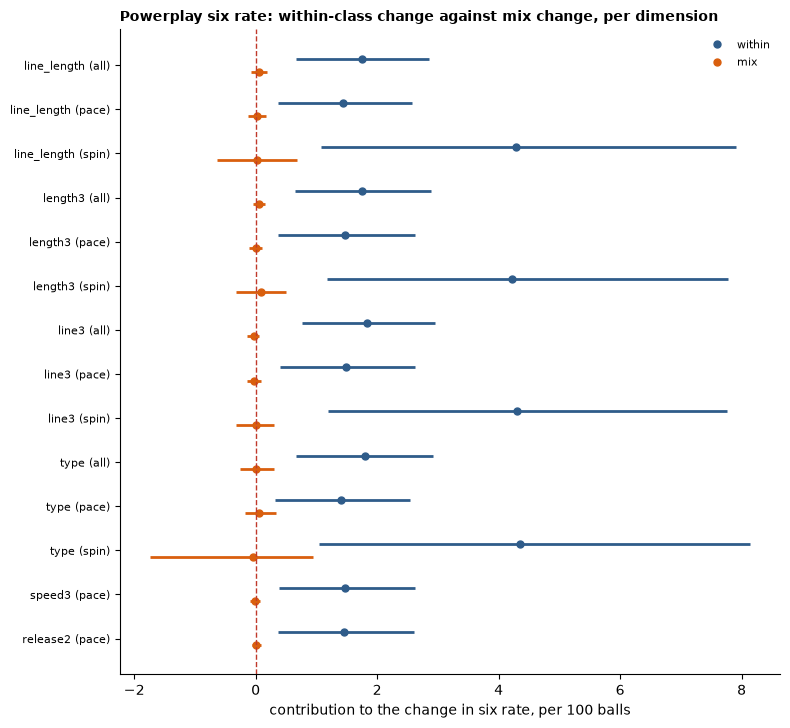

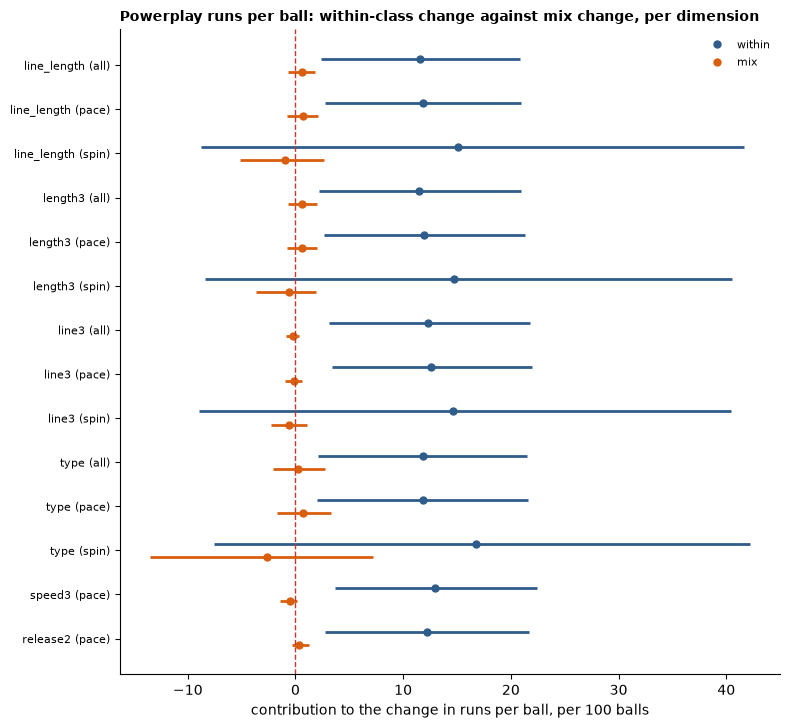

In [7]:
fig = mm.plot_components(comp, "powerplay", "six_rate", "Powerplay six rate: within-class change against mix change, per dimension")
results_io.write_figure(fig, settings, ANALYSIS, "shift_share_six_rate", SEED, PRODUCER)
plt.show()
fig = mm.plot_components(comp, "powerplay", "runs_per_ball", "Powerplay runs per ball: within-class change against mix change, per dimension")
results_io.write_figure(fig, settings, ANALYSIS, "shift_share_runs_per_ball", SEED, PRODUCER)
plt.show()

## The delivery menu

Per class: share of powerplay deliveries in both seasons and its change in points, six rate and runs per ball in both seasons with the change and its interval, wicket rate, the class's contribution to the within and mix components, and the thin flag. Shown for line by length (all and pace), type, speed and release; the full table is written.

In [8]:
menu = result["menu"]
cols = ["class", f"balls_{YEARS[0]}", f"balls_{YEARS[1]}", f"share_{YEARS[0]}", f"share_{YEARS[1]}", "share_change_points",
        f"six_rate_{YEARS[0]}", f"six_rate_{YEARS[1]}", "six_rate_change", "six_rate_change_low", "six_rate_change_high",
        f"runs_per_ball_{YEARS[0]}", f"runs_per_ball_{YEARS[1]}", "runs_per_ball_change",
        f"wicket_rate_{YEARS[0]}", f"wicket_rate_{YEARS[1]}", "six_within_contribution", "six_mix_contribution", "thin"]
for dimension, kind in (("line_length", "all"), ("line_length", "pace"), ("type", "all"), ("speed3", "pace"), ("release2", "pace")):
    print(f"--- {dimension}, {kind}")
    display(menu[(menu["dimension"] == dimension) & (menu["kind"] == kind)][cols].round(3))

--- line_length, all


,class,balls_2023,balls_2024,share_2023,share_2024,share_change_points,six_rate_2023,six_rate_2024,six_rate_change,six_rate_change_low,six_rate_change_high,runs_per_ball_2023,runs_per_ball_2024,runs_per_ball_change,wicket_rate_2023,wicket_rate_2024,six_within_contribution,six_mix_contribution,thin
0,full|leg,69,72,0.013,0.014,0.105,0.087,0.042,-0.045,-0.135,0.038,1.725,1.833,0.109,0.000,0.028,-0.001,0.000,True
1,full|off,602,719,0.114,0.141,2.689,0.045,0.068,0.023,0.000,0.046,1.558,1.766,0.208,0.035,0.043,0.003,0.002,False
2,full|stumps,443,530,0.084,0.104,1.997,0.070,0.102,0.032,-0.003,0.068,1.605,1.872,0.267,0.052,0.064,0.003,0.002,False
3,good|leg,139,109,0.026,0.021,-0.494,0.036,0.119,0.083,0.007,0.164,1.482,1.697,0.215,0.022,0.018,0.002,-0.000,True
4,good|off,1135,1170,0.214,0.229,1.440,0.030,0.043,0.013,-0.004,0.029,1.219,1.297,0.079,0.039,0.042,0.003,0.001,False
5,good|stumps,803,809,0.152,0.158,0.652,0.055,0.059,0.005,-0.021,0.030,1.238,1.266,0.028,0.042,0.052,0.001,0.000,False
6,short|leg,191,170,0.036,0.033,-0.284,0.099,0.147,0.048,-0.027,0.122,1.843,1.841,-0.002,0.021,0.047,0.002,-0.000,True
7,short|off,1230,1010,0.232,0.198,-3.485,0.037,0.052,0.016,-0.002,0.034,1.437,1.516,0.078,0.041,0.034,0.003,-0.002,False
8,short|stumps,675,519,0.128,0.102,-2.603,0.044,0.060,0.015,-0.013,0.044,1.336,1.518,0.182,0.046,0.048,0.002,-0.001,False
9,untagged,5,4,0.001,0.001,-0.016,0.200,0.000,-0.200,-0.667,0.000,2.200,0.000,-2.200,0.200,0.000,-0.000,-0.000,True


--- line_length, pace


,class,balls_2023,balls_2024,share_2023,share_2024,share_change_points,six_rate_2023,six_rate_2024,six_rate_change,six_rate_change_low,six_rate_change_high,runs_per_ball_2023,runs_per_ball_2024,runs_per_ball_change,wicket_rate_2023,wicket_rate_2024,six_within_contribution,six_mix_contribution,thin
10,full|leg,48,56,0.011,0.013,0.137,0.062,0.036,-0.027,-0.122,0.054,1.667,1.786,0.119,0.000,0.018,-0.000,0.000,True
11,full|off,474,639,0.113,0.146,3.313,0.038,0.063,0.025,0.001,0.048,1.561,1.745,0.184,0.032,0.042,0.003,0.002,False
12,full|stumps,313,428,0.074,0.098,2.325,0.067,0.086,0.019,-0.020,0.059,1.565,1.867,0.301,0.042,0.061,0.002,0.002,False
13,good|leg,95,95,0.023,0.022,-0.090,0.042,0.116,0.074,-0.002,0.154,1.600,1.705,0.105,0.011,0.021,0.002,-0.000,True
14,good|off,891,1002,0.212,0.228,1.687,0.028,0.041,0.013,-0.005,0.030,1.200,1.306,0.107,0.038,0.043,0.003,0.001,False
15,good|stumps,544,615,0.129,0.140,1.103,0.059,0.046,-0.013,-0.042,0.014,1.221,1.208,-0.012,0.050,0.060,-0.002,0.001,False
16,short|leg,172,161,0.041,0.037,-0.414,0.105,0.143,0.038,-0.040,0.115,1.907,1.839,-0.068,0.023,0.050,0.001,-0.001,True
17,short|off,1077,912,0.256,0.208,-4.782,0.036,0.056,0.020,0.001,0.039,1.410,1.521,0.110,0.043,0.035,0.005,-0.002,False
18,short|stumps,592,476,0.141,0.109,-3.206,0.044,0.055,0.011,-0.019,0.041,1.301,1.477,0.176,0.051,0.053,0.001,-0.002,False
19,untagged,5,2,0.001,0.000,-0.073,0.200,0.000,-0.200,-0.667,0.000,2.200,0.000,-2.200,0.200,0.000,-0.000,-0.000,True


--- type, all


,class,balls_2023,balls_2024,share_2023,share_2024,share_change_points,six_rate_2023,six_rate_2024,six_rate_change,six_rate_change_low,six_rate_change_high,runs_per_ball_2023,runs_per_ball_2024,runs_per_ball_change,wicket_rate_2023,wicket_rate_2024,six_within_contribution,six_mix_contribution,thin
54,bouncer,99,139,0.019,0.027,0.848,0.071,0.101,0.030,-0.042,0.100,1.313,1.727,0.413,0.051,0.058,0.001,0.001,True
55,cutter,261,187,0.049,0.037,-1.274,0.057,0.070,0.012,-0.036,0.059,1.448,1.888,0.439,0.042,0.021,0.001,-0.001,True
56,finger_spin,556,547,0.105,0.107,0.194,0.058,0.084,0.027,-0.010,0.065,1.504,1.590,0.087,0.038,0.037,0.003,0.000,False
57,other_rare,1,0,0.000,0.000,-0.019,0.000,NaN,NaN,NaN,NaN,0.000,NaN,NaN,0.000,NaN,0.000,-0.000,True
58,seam_stock,2162,2675,0.409,0.523,11.474,0.048,0.068,0.020,0.006,0.034,1.448,1.615,0.168,0.037,0.044,0.009,0.007,False
59,slower_ball_deception,746,281,0.141,0.055,-8.600,0.048,0.050,0.002,-0.041,0.038,1.440,1.459,0.019,0.039,0.057,0.000,-0.004,True
60,swing,1091,1117,0.206,0.219,1.235,0.027,0.037,0.010,-0.007,0.027,1.152,1.180,0.028,0.047,0.048,0.002,0.000,False
61,wrist_spin,374,166,0.071,0.032,-3.820,0.051,0.096,0.046,-0.011,0.111,1.545,1.452,-0.094,0.043,0.042,0.002,-0.003,True
62,yorker,2,0,0.000,0.000,-0.038,0.000,NaN,NaN,NaN,NaN,0.500,NaN,NaN,0.000,NaN,0.000,-0.000,True


--- speed3, pace


,class,balls_2023,balls_2024,share_2023,share_2024,share_change_points,six_rate_2023,six_rate_2024,six_rate_change,six_rate_change_low,six_rate_change_high,runs_per_ball_2023,runs_per_ball_2024,runs_per_ball_change,wicket_rate_2023,wicket_rate_2024,six_within_contribution,six_mix_contribution,thin
79,over_140,707,744,0.168,0.170,0.174,0.031,0.070,0.039,0.016,0.063,1.355,1.536,0.181,0.048,0.050,0.007,0.000,False
80,130_to_140,2121,2422,0.504,0.552,4.853,0.042,0.059,0.017,0.003,0.030,1.334,1.491,0.157,0.045,0.045,0.009,0.002,False
81,under_130,1245,1074,0.296,0.245,-5.078,0.053,0.054,0.001,-0.019,0.020,1.455,1.563,0.108,0.028,0.044,0.000,-0.003,False
82,untagged,138,146,0.033,0.033,0.052,0.065,0.041,-0.024,-0.079,0.027,1.616,1.233,-0.383,0.043,0.048,-0.001,0.000,True


--- release2, pace


,class,balls_2023,balls_2024,share_2023,share_2024,share_change_points,six_rate_2023,six_rate_2024,six_rate_change,six_rate_change_low,six_rate_change_high,runs_per_ball_2023,runs_per_ball_2024,runs_per_ball_change,wicket_rate_2023,wicket_rate_2024,six_within_contribution,six_mix_contribution,thin
83,over_2.0m,1406,1687,0.334,0.385,5.075,0.046,0.059,0.014,-0.005,0.032,1.468,1.513,0.045,0.043,0.054,0.005,0.003,False
84,2.0m_or_lower,2667,2553,0.633,0.582,-5.126,0.043,0.060,0.017,0.003,0.031,1.326,1.521,0.195,0.039,0.040,0.010,-0.003,False
85,untagged,138,146,0.033,0.033,0.052,0.065,0.041,-0.024,-0.079,0.027,1.616,1.233,-0.383,0.043,0.048,-0.001,0.000,True


Three reads come out of the menu.

*What moved.* The mix went fuller and faster and lost its variation. Full outside off rose 2.7 points of share and short outside off fell 3.5; stock seam rose from 41% to 52% of powerplay deliveries while the slower ball fell from 14% to 5.5% and wrist spin from 7% to 3%; the 130 to 140 band rose 4.9 points at the expense of balls under 130; releases above 2.0 metres rose 5 points. Bowlers bowled more stock deliveries, harder and from higher, and cut the slower ball by more than half.

*What held.* Three classes did not concede more sixes: balls under 130 kph (5.3% to 5.4%, interval −1.9 to +2.0) whose wicket rate rose from 2.8% to 4.4%; the slower-ball family (4.8% to 5.0%, on a thin 2024 count); and the good length on the stumps (5.5% to 5.9%, interval −2.1 to +3.0). Good length outside off nearly held (3.0% to 4.3%).

*What was punished.* Balls over 140 kph went from the safest class in 2023 (3.1%) to the most hit in 2024 (7.0%; change +3.9, interval +1.6 to +6.3), and the 130 to 140 band rose 1.7 (clears). Full outside off rose 2.3 (interval 0.0 to +4.6), full on the stumps 3.2 (−0.3 to +6.8), stock seam 2.0 (+0.6 to +3.4), spin of both kinds. In 2023 the slow ball was the most hit delivery and pace the least; in 2024 that inverted. The batters adapted to pace, and the one class that resisted them, the slower delivery, is the one bowlers stopped bowling.

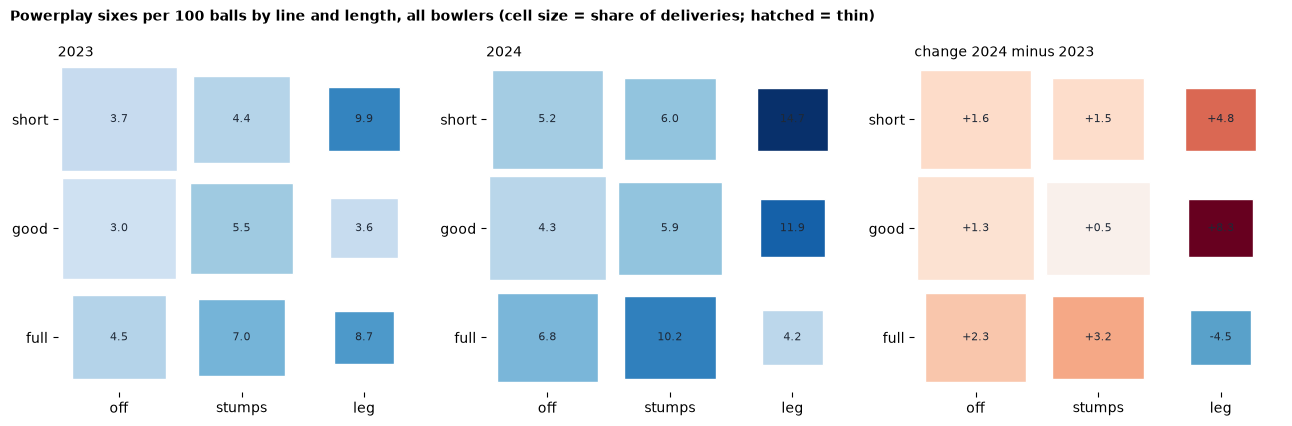

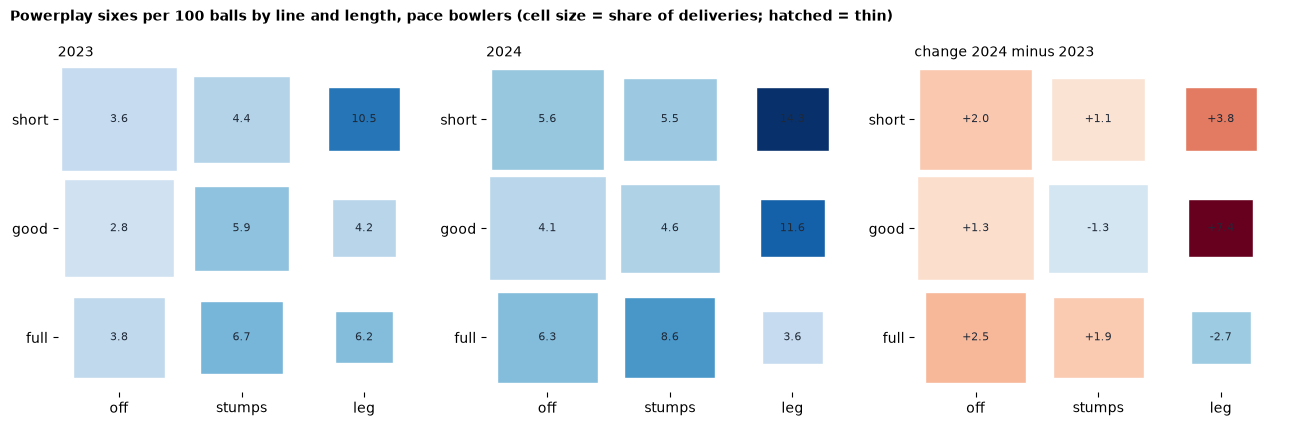

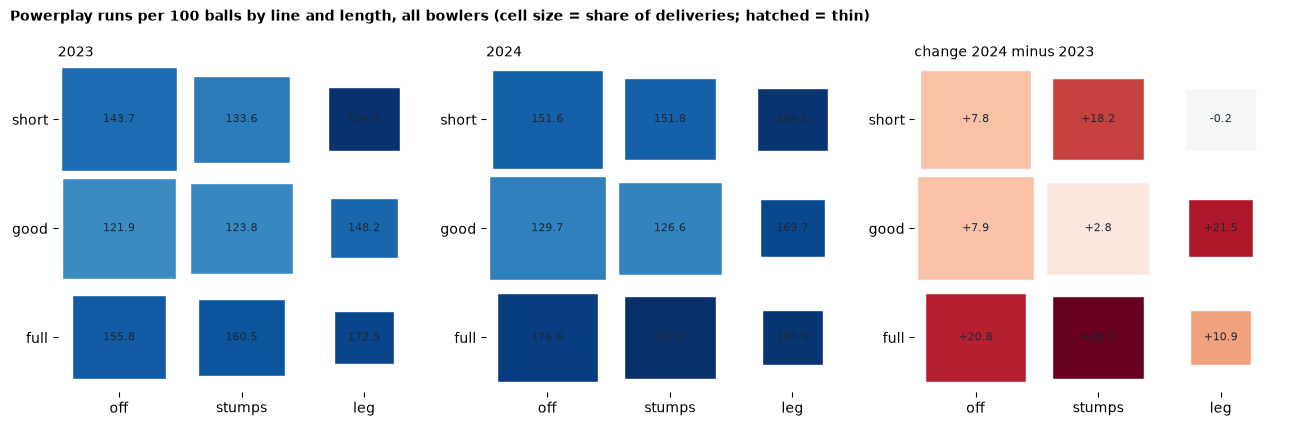

In [9]:
for kind in ("all", "pace"):
    fig = mm.plot_line_length_grid(menu, YEARS[0], YEARS[1], kind=kind, rate="six_rate",
                                   title=f"Powerplay sixes per 100 balls by line and length, {kind} bowlers (cell size = share of deliveries; hatched = thin)")
    results_io.write_figure(fig, settings, ANALYSIS, f"line_length_grid_six_rate_{kind}", SEED, PRODUCER)
    plt.show()
fig = mm.plot_line_length_grid(menu, YEARS[0], YEARS[1], kind="all", rate="runs_per_ball",
                               title="Powerplay runs per 100 balls by line and length, all bowlers (cell size = share of deliveries; hatched = thin)")
results_io.write_figure(fig, settings, ANALYSIS, "line_length_grid_runs_per_ball_all", SEED, PRODUCER)
plt.show()

## Same attacks or different bowlers

The league powerplay six rate conceded decomposed over bowlers, on the shared draws; the per-bowler table at the 60-ball floor; the continuing-bowlers-only contrast beside the all-bowler contrast; and the same decomposition for runs per ball.

In [10]:
bowlers = continuity.run_decomposition(df, settings, SEED, "six_rate", "powerplay", n_iter=N_ITER, player_column="p_bowl")
print("bowlers:", bowlers["n_batters"], "| identity max abs error:", bowlers["components"].attrs["identity_max_abs_error"])
results_io.write_table(bowlers["components"], settings, ANALYSIS, "bowler_six_rate_components", SEED, PRODUCER, EXTRA)
results_io.write_table(bowlers["batters"], settings, ANALYSIS, "bowler_six_rate_by_bowler", SEED, PRODUCER, EXTRA)
display(bowlers["components"].round(5))
bowlers["batters"][bowlers["batters"]["meets_floor_both_seasons"]].head(20).round(4)

bowlers: {'continuing': 64, 'entrants': 37, 'exits': 45, 'continuing_meeting_floor': 28} | identity max abs error: 1.3877787807814457e-17


,quantity,estimate,ci_low,ci_high,p_positive,interval_method
0,league_earlier,0.04623,0.04014,0.05276,1.0000,percentile
1,league_later,0.06425,0.05536,0.07379,1.0000,percentile
2,league_change,0.01802,0.00699,0.02924,0.9995,percentile
3,within,0.01504,0.00426,0.02463,0.9982,percentile
4,composition,0.00298,-0.00476,0.01240,0.8096,percentile
5,composition_continuing_reweight,-0.00222,-0.00795,0.00644,0.4264,percentile
6,composition_entrants,0.02005,0.01595,0.02704,1.0000,percentile
7,composition_exits,-0.01485,-0.02146,-0.01257,0.0000,percentile
8,share_later_faced_by_entrants,0.26460,0.23477,0.33989,1.0000,percentile
9,share_earlier_faced_by_exits,0.26931,0.25939,0.36319,1.0000,percentile


,p_bat,bat,status,balls_2023,balls_2024,rate_2023,rate_2024,rate_change,change_low,change_high,within_contribution,meets_floor_both_seasons
0,940973,Mohammed Siraj,continuing,180,168,0.0222,0.0774,0.0552,-0.0056,0.1219,0.0018,True
4,550215,Kagiso Rabada,continuing,73,120,0.0959,0.0333,-0.0626,-0.1221,0.0142,-0.0012,True
6,1312645,Harshit Rana,continuing,85,84,0.0471,0.1071,0.0601,0.0028,0.1310,0.0010,True
9,236779,Ishant Sharma,continuing,102,108,0.0098,0.0556,0.0458,-0.0111,0.1176,0.0009,True
12,376116,Umesh Yadav,continuing,84,102,0.0952,0.0490,-0.0462,-0.1275,0.0341,-0.0008,True
13,326016,Bhuvneshwar Kumar,continuing,168,240,0.0298,0.0500,0.0202,-0.0165,0.0611,0.0008,True
14,822553,Tushar Deshpande,continuing,195,150,0.0513,0.0733,0.0221,-0.0171,0.0617,0.0007,True
15,1070196,Yash Thakur,continuing,36,54,0.1389,0.0556,-0.0833,-0.2150,0.0500,-0.0007,True
18,1209292,Vaibhav Arora,continuing,56,149,0.0179,0.0537,0.0358,-0.0166,0.0838,0.0007,True
19,694211,Avesh Khan,continuing,72,78,0.0278,0.0769,0.0491,-0.0251,0.1296,0.0007,True


In [11]:
bowler_contrast = continuity.continuing_batter_contrast(df, settings, SEED, "six_rate", "powerplay", bowlers["counts"],
                                                        int(CFG["bowler_min_balls"]), player_column="p_bowl")
results_io.write_table(bowler_contrast, settings, ANALYSIS, "bowler_continuing_contrast", SEED, PRODUCER, EXTRA)
display(bowler_contrast[["theme", "estimate", "ci_low", "ci_high", "interval_method", "resampling_stable", "n_continuing_batters"]].round(4))
bowlers_rpb = continuity.run_decomposition(df, settings, SEED, "run_rate", "powerplay", n_iter=N_ITER, counts=bowlers["counts"], player_column="p_bowl")
results_io.write_table(bowlers_rpb["components"], settings, ANALYSIS, "bowler_run_rate_components", SEED, PRODUCER, EXTRA)
bowlers_rpb["components"].round(4)

,theme,estimate,ci_low,ci_high,interval_method,resampling_stable,n_continuing_batters
0,powerplay_six_rate_diff_all_batters,0.0180,0.0069,0.0297,bootstrap_t,True,18
1,powerplay_six_rate_ratio_all_batters,1.3898,1.1353,1.7002,bootstrap_t,True,18
2,powerplay_six_rate_diff_continuing_batters_only,0.0137,0.0010,0.0272,bootstrap_t,True,18
3,powerplay_six_rate_ratio_continuing_batters_only,1.3641,1.0270,1.8368,bootstrap_t,True,18


,quantity,estimate,ci_low,ci_high,p_positive,interval_method
0,league_earlier,8.3719,8.0397,8.7078,1.0000,percentile
1,league_later,9.0998,8.6655,9.5669,1.0000,percentile
2,league_change,0.7279,0.1685,1.3003,0.9957,percentile
3,within,0.4742,-0.0230,0.9123,0.9677,percentile
4,composition,0.2537,-0.0615,0.6341,0.9491,percentile
5,composition_continuing_reweight,0.0899,-0.4381,0.9501,0.7748,percentile
6,composition_entrants,2.4484,2.1608,3.1678,1.0000,percentile
7,composition_exits,-2.2846,-3.1005,-2.1769,0.0000,percentile
8,share_later_faced_by_entrants,0.2629,0.2336,0.3380,1.0000,percentile
9,share_earlier_faced_by_exits,0.2689,0.2588,0.3628,1.0000,percentile


The same bowlers were hit harder. Of the +1.8 per 100 balls, continuing bowlers account for +1.5 (interval +0.4 to +2.5, 83% of the change) and different bowlers for +0.3 (−0.5 to +1.2). Entrants did concede more than the bowlers they replaced (7.6% against 5.5% on about a quarter of the balls each), but the two nearly cancel. Continuing bowlers' six rate conceded rose from 4.3% to 6.0%, a ratio of 1.36 (interval 1.03 to 1.84) against 1.39 for all bowlers; runs per ball split 65% within and 35% composition. Of the 28 continuing bowlers at the floor, only Harshit Rana's change clears (4.7% to 10.7%); Mohammed Siraj (2.2% to 7.7%) sits just short; Kagiso Rabada went the other way. This is the mirror of the batting finding: on the bowling side the change was overwhelmingly the same attacks conceding more, not turnover.

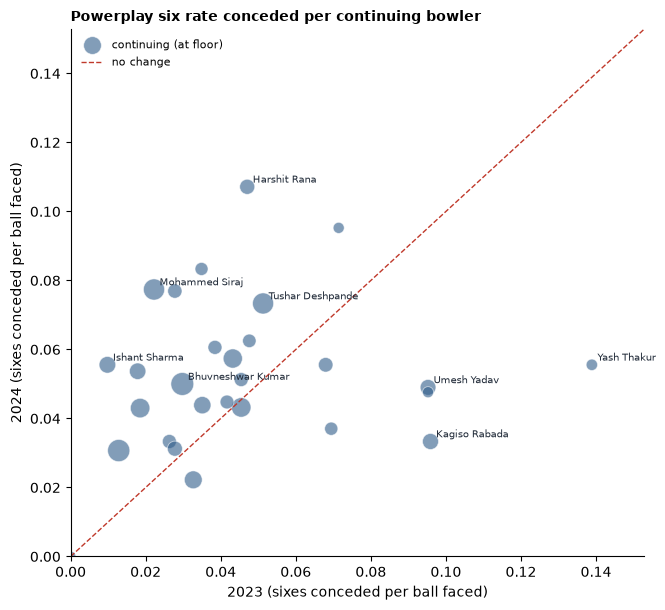

In [12]:
fig = continuity.plot_batter_scatter(bowlers["batters"], YEARS[0], YEARS[1], "sixes conceded per ball faced", "Powerplay six rate conceded per continuing bowler")
results_io.write_figure(fig, settings, ANALYSIS, "bowler_six_rate_scatter", SEED, PRODUCER)
plt.show()

There was no line-and-length answer to the powerplay surge. Ninety-seven percent of the extra sixes came from every class of delivery being hit harder, not from what was bowled; the mix did change (fuller, faster, more stock seam, far fewer slower balls, higher releases) but the shifts netted to nothing, and the same bowlers conceded most of the increase. The classes that held were the slower delivery (under 130 kph, which also took more wickets) and the good length on the stumps, and the slower delivery is the one bowlers cut by more than half. For a bowling coach the finding is that the 2024 powerplay was won by batters adapting to pace, the fast ball went from safest to most hit, and the one delivery with evidence of resisting the surge was bowled a third as often as before.